# Head movement analysis: extraction, spectrograms and nod measures

This tutorial shows how to
1. extract head pose (pitch, yaw, roll, head position), iris gaze and eye aspect ratio from a video with `head_movement_analysis.py`;
2. look at the head-movement time series and compute head angular speed;
3. compute a **wavelet spectrogram** of head pitch (nodding);
4. compute the published **nod measures**:
   - **fast nod score**: mean wavelet power of head pitch in 2.6–6.5 Hz (Falk et al. 2023, from Hale et al. 2020); fast nodding is a listener behaviour;
   - **slow nod coherence**: wavelet coherence between two partners' head pitch in 0.2–1.1 Hz, compared with pseudo partners who never met (Hale et al. 2020).

References
- Hale, Ward, Buccheri, Oliver & Hamilton (2020). *Are you on my wavelength? Interpersonal coordination in dyadic conversations.* Journal of Nonverbal Behavior, 44, 63–83.
- Falk et al. (2023). *Head nods in three conversational contexts* (Research Square preprint, doi 10.21203/rs.3.rs-3526068/v1).
- Grinsted, Moore & Jevrejeva (2004); Torrence & Compo (1998): wavelet coherence and the cone of influence.

## Environment and models
Same environment as the face analysis tutorial (`face_analysis_tutorial.md`):
```
conda create --name mediapipe python=3.11
conda activate mediapipe
pip install mediapipe scipy polars matplotlib
```
Face model (the same one as for the blendshapes):
```
wget -O models/face_landmarker_v2_with_blendshapes.task -q https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task
```
**Change the paths in the next cell** to point to your videos, model and outputs.

In [1]:
import sys, glob, os
sys.path.append("/Users/arias/Documents/Developement/video_analysis")   # path to this repository
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import head_movement_analysis as hm

FPS = 30
MODEL = "/Users/arias/Documents/Developement/ducksoup/mp_plugins/models/face_landmarker.task"
# one DuckSoup recording (participant p4 of a dyad)
VIDEO = ("/Users/arias/Documents/Developement/article_scripts/ducksoup_methods_paper/data/preproc_v2_samples/"
         "i-b713f25e1b977e73547606decb3deb52-a-20240202-153811.604-s-mkreal_meeting_experiment_prolific3-n-1-p4p8-u-p4-c-1-dry.mp4")
OUT = "tutorial_output/"
# a folder of csvs already extracted for every video (e.g. with analyse_video_parallel on the HPC), used in part 5
HEAD_FOLDER = "/Users/arias/Documents/Developement/article_scripts/exploratory_analyses/data/face_data/mediapipe_results/head_gaze_v3/"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

## 1. Extraction
`analyse_video` writes `<file_tag>.csv` (one row per frame with a face) and, with `export_lmks=True`, `<file_tag>_lmks.csv` (rigid points, eyelids, irises).
Frame numbering is the same as `face_analysis_mp.analyse_video`, so frame *k* matches frame *k* of the blendshape csv.
For many videos, use `analyse_video_parallel(sources="preproc/.../*.mp4", ..., n_jobs=...)`, or call `analyse_video` from several HPC jobs: they share the work through the `processing` folder.

In [2]:
hm.analyse_video(VIDEO, target_analysis_folder=OUT + "head_movement/", target_processing_folder=OUT + "processing/",
                 model_asset_path=MODEL, export_lmks=True)
csv = OUT + "head_movement/" + os.path.basename(VIDEO)[:-4] + ".csv"
df = hm.load_head_movement(csv)          # full frame grid: frames without a face are NaN
print(df.shape)
df.select("frame", "pitch", "yaw", "roll", "tx", "ty", "tz", "iris_x_l", "ear_l").head()

Starting analysis for : /Users/arias/Documents/Developement/article_scripts/ducksoup_methods_paper/data/preproc_v2_samples/i-b713f25e1b977e73547606decb3deb52-a-20240202-153811.604-s-mkreal_meeting_experiment_prolific3-n-1-p4p8-u-p4-c-1-dry.mp4


I0000 00:00:1792505005.337300 1656432 init-domain.cc:128] Fiber init: default domain = pthread, concurrency = 11, prefix = pthread-default
W0000 00:00:1792505005.347784 1656432 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1792505005.420950 1656432 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M1 Max
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792505005.422420 1656435 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792505005.432523 1656434 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Finished processing frames, processed 7499 frames, face in 6005, for file : i-b713f25e1b977e73547606decb3deb52-a-20240202-153811.604-s-mkreal_meeting_experiment_prolific3-n-1-p4p8-u-p4-c-1-dry
Finished all for : /Users/arias/Documents/Developement/article_scripts/ducksoup_methods_paper/data/preproc_v2_samples/i-b713f25e1b977e73547606decb3deb52-a-20240202-153811.604-s-mkreal_meeting_experiment_prolific3-n-1-p4p8-u-p4-c-1-dry.mp4 (52.8 s)
(7499, 25)


frame,pitch,yaw,roll,tx,ty,tz,iris_x_l,ear_l
i64,f64,f64,f64,f64,f64,f64,f64,f64
0,-1.46758,-3.25245,-0.08013,5.53803,-10.02197,-48.65662,0.50131,0.10824
1,-1.69155,-3.28501,0.02156,5.52301,-9.9921,-48.47226,0.49915,0.10675
2,-2.22159,-3.31201,-0.00408,5.52026,-9.99568,-48.38448,0.49139,0.09102
3,-2.74185,-3.43184,0.20699,5.54345,-10.03661,-48.50688,0.49263,0.07326
4,-2.94139,-3.50454,0.32803,5.54838,-10.04648,-48.53191,0.48556,0.05649


## 2. Time series
- **pitch:** > 0 = head down (nodding); **yaw:** > 0 = nose towards image right; **roll:** tilt. All in degrees, from MediaPipe's facial transformation matrix.
- **tz:** distance to the camera (cm; closer = larger).
- **Head angular speed:** the angles are low-passed at 8 Hz first, to remove frame-level tracker jitter.

median head speed 3.6 deg/s, face found in 80.1% of frames


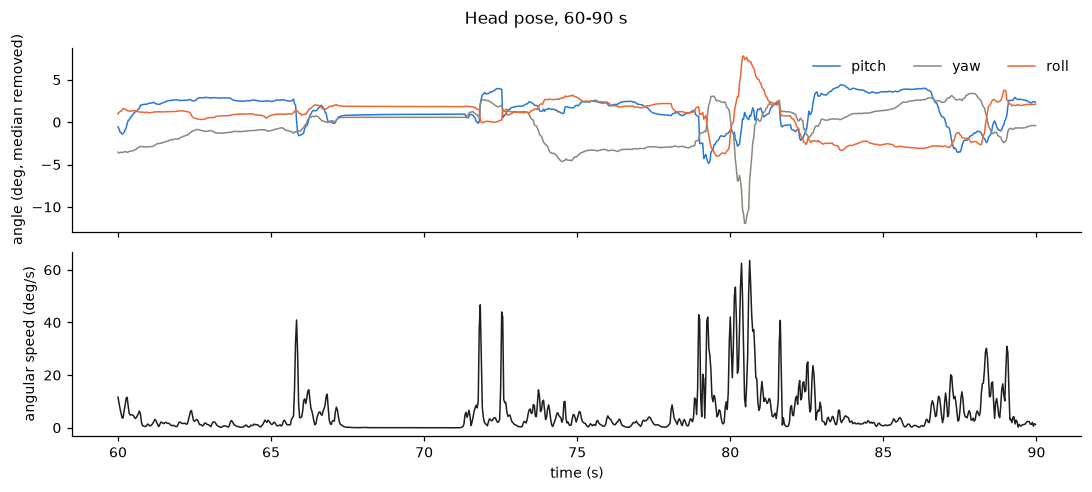

In [3]:
t = df["frame"].to_numpy() / FPS
speed = hm.head_angular_speed(df, FPS)
sl = (t >= 60) & (t < 90)
fig, axs = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
for c, col in (("pitch", "#2a78d6"), ("yaw", "#8a897f"), ("roll", "#eb6834")):
    x = df[c].to_numpy()
    axs[0].plot(t[sl], x[sl] - np.nanmedian(x), lw=1, color=col, label=c)
axs[0].set_ylabel("angle (deg, median removed)"); axs[0].legend(frameon=False, ncol=3)
axs[1].plot(t[sl], speed[sl], lw=1, color="#1f1f1e"); axs[1].set_ylabel("angular speed (deg/s)"); axs[1].set_xlabel("time (s)")
fig.suptitle("Head pose, 60-90 s"); fig.tight_layout()
print(f"median head speed {np.nanmedian(speed):.1f} deg/s, face found in {np.isfinite(df['pitch'].to_numpy()).mean():.1%} of frames")

## 3. Wavelet spectrogram of head pitch
Morlet wavelet (w0 = 6), as in Hale et al. (2020) with the Grinsted toolbox. Points inside the **cone of influence** (close to the edges or to gaps in the tracking) are unreliable, so they are set to NaN (white).
Dashed lines mark the two nod bands of Hale et al.: **slow** 0.2–1.1 Hz (coordinated, mimicry-like nodding) and **fast** 2.6–6.5 Hz (small, quick listener nods).

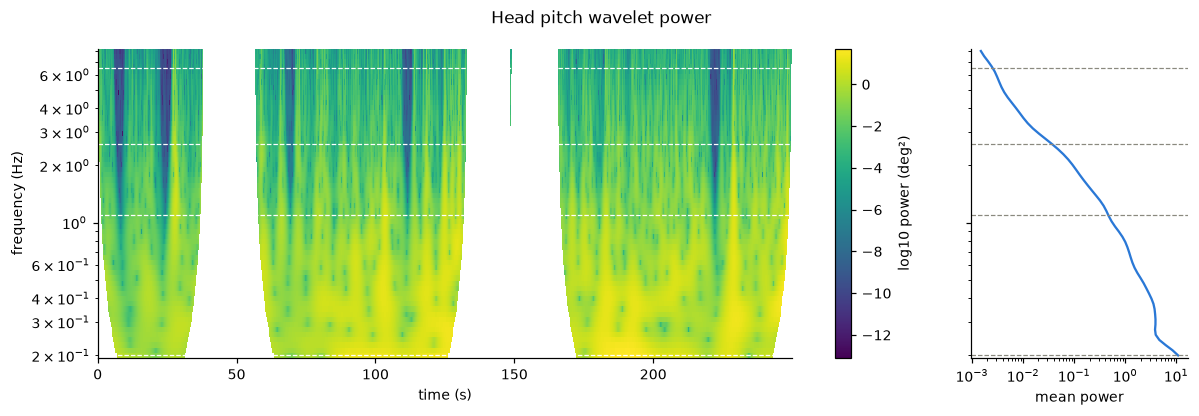

In [4]:
freqs = np.geomspace(0.2, 8.0, 60)
pitch = hm.fill_short_gaps(df["pitch"].to_numpy())
P = hm.wavelet_power(pitch, FPS, freqs)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [4, 1]}, sharey=True)
im = axs[0].pcolormesh(t, freqs, np.log10(P), shading="auto", cmap="viridis")
axs[0].set_yscale("log"); axs[0].set_ylabel("frequency (Hz)"); axs[0].set_xlabel("time (s)")
for f in (0.2, 1.1, 2.6, 6.5):
    axs[0].axhline(f, color="white", lw=0.8, ls="--")
fig.colorbar(im, ax=axs[0], label="log10 power (deg²)")
axs[1].plot(np.nanmean(P, axis=1), freqs, color="#2a78d6")          # time-averaged ("global") spectrum
axs[1].set_xscale("log"); axs[1].set_xlabel("mean power")
for f in (0.2, 1.1, 2.6, 6.5):
    axs[1].axhline(f, color="#8a897f", lw=0.8, ls="--")
fig.suptitle("Head pitch wavelet power"); fig.tight_layout()

**Reading the spectrogram**
- **White areas:** inside the cone of influence. Here the face was lost around 37–57 s and 133–170 s (the participant left the frame), and the cone widens towards low frequencies around these gaps.
- **Dark vertical stripes** (power ~1e-11), e.g. around 23, 112 and 223 s: **video freezes** (network stalls). The tracked pitch stays constant to ~0.001° for a second or more, against ~0.7° per second for a real head. Re-encoding adds tiny jitter, so an exact-equality test does not catch them; a near-zero spread over ~1 s does.
- **Power falls with frequency:** fast nods (2.6–6.5 Hz) carry little power compared with slow head movements, as expected (they are small).

## 4. Fast nod score (Falk et al. 2023)
The mean wavelet power of head pitch in 2.6–6.5 Hz, outside the cone of influence. Hale et al. (2020) found that fast nodding comes from the listener, so in conversation data compute it over **listening frames**: pass `mask=` (partner speaking, self silent, from your speech analysis). Here we show the whole recording and its two halves.

In [5]:
n = len(pitch)
first = np.arange(n) < n // 2
print(f"fast nod score, whole recording: {hm.fast_nod_score(pitch, FPS):.4f} deg²")
print(f"first half: {hm.fast_nod_score(pitch, FPS, mask=first):.4f}   second half: {hm.fast_nod_score(pitch, FPS, mask=~first):.4f}")
# with speech: listening = partner talks and self silent, e.g.
# listening = partner_talking & ~own_talking            (boolean arrays on the same 30 fps frame grid)
# hm.fast_nod_score(pitch, FPS, mask=listening)

fast nod score, whole recording: 0.0110 deg²
first half: 0.0090   second half: 0.0134


## 5. Slow nod coherence between partners (Hale et al. 2020)
The wavelet coherence of the two partners' head pitch, averaged over 0.2–1.1 Hz and over time (cone of influence excluded).
Coherence is never zero, even between strangers, so it must be compared with **pseudo partners**: recordings of people who never interacted (here, other sessions). The interesting quantity is real − pseudo.
This part uses csvs already extracted for every recording (`HEAD_FOLDER`).

slow nod coherence, real partners: 0.465


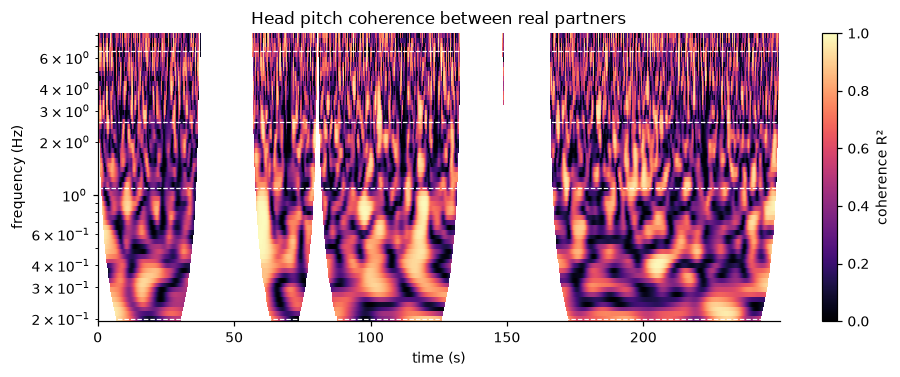

In [6]:
files = sorted(f for f in glob.glob(HEAD_FOLDER + "*-dry.csv") if not f.endswith("_lmks.csv"))
tag = lambda f: os.path.basename(f)[:-4]
session = lambda f: tag(f).split("-s-")[1].split("-n-")[0]
a = next(f for f in files if "prolific3-n-1-p4p8-u-p4-" in f)        # participant p4
b = next(f for f in files if "prolific3-n-1-p4p8-u-p8-" in f)        # their real partner p8
N = 250 * FPS                                                          # same clock: frame k = k/30 s from the start
pa = hm.load_head_movement(a, N)["pitch"].to_numpy()
pb = hm.load_head_movement(b, N)["pitch"].to_numpy()
R2 = hm.wavelet_coherence(hm.fill_short_gaps(pa), hm.fill_short_gaps(pb), FPS, freqs)
tt = np.arange(N) / FPS
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.pcolormesh(tt, freqs, R2, shading="auto", cmap="magma", vmin=0, vmax=1)
ax.set_yscale("log"); ax.set_ylabel("frequency (Hz)"); ax.set_xlabel("time (s)")
for f in (0.2, 1.1, 2.6, 6.5):
    ax.axhline(f, color="white", lw=0.8, ls="--")
fig.colorbar(im, ax=ax, label="coherence R²"); ax.set_title("Head pitch coherence between real partners")
real = hm.slow_nod_coherence(pa, pb, FPS)
print(f"slow nod coherence, real partners: {real:.3f}")

real - mean pseudo = +0.0113


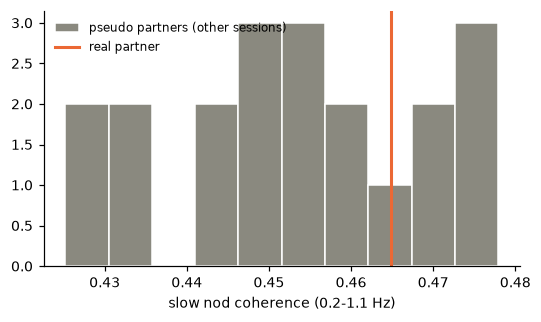

In [7]:
rng = np.random.default_rng(0)
others = [f for f in files if session(f) != session(a)]
pseudo = [hm.slow_nod_coherence(pa, hm.load_head_movement(f, N)["pitch"].to_numpy(), FPS)
          for f in rng.choice(others, 20, replace=False)]
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(pseudo, bins=10, color="#8a897f", edgecolor="white", label="pseudo partners (other sessions)")
ax.axvline(real, color="#eb6834", lw=2, label="real partner")
ax.set_xlabel("slow nod coherence (0.2-1.1 Hz)"); ax.legend(frameon=False, fontsize=8); fig.tight_layout()
print(f"real - mean pseudo = {real - np.mean(pseudo):+.4f}")